# Bài 2 — Giải Tic-Tac-Toe bằng AND-OR Tree Search (`tictactoe_and_or_tree_search.ipynb`)

**Thành viên phụ trách:** Hải  
**Protocol thí nghiệm:** Bộ 4 trạng thái chuẩn `T1–T4`, `SEED = 42`, `DEBUG = 0` khi benchmark, đồng hồ `time.perf_counter()`, reset `COUNT` ở mỗi lần tìm kiếm, thi đấu với `random_player` tối thiểu 100 ván mỗi vai (`X` và `O`).

## 1. Giới thiệu mô hình AND-OR Tree Search trong trò chơi đối kháng

Trong bài toán tìm kiếm với hành động không xác định (Nondeterministic Search — AIMA Chương 4), đối thủ được xem như một phần của môi trường:
* **Nút OR (`or_search`):** Đại diện cho lượt đi của tác tử (`player`). Tác tử chỉ cần tìm **ít nhất một** hành động `action` sao cho kế hoạch con trả về khác `None`.
* **Hàm chuyển trạng thái không xác định (`results(state, action, player)`):** Sau khi `player` đặt quân vào ô `action`, đối thủ (`opponent = other(player)`) có thể phản ứng ở bất kỳ ô trống nào còn lại. Do đó một hành động tạo ra một **tập hợp các trạng thái kế tiếp**.
* **Nút AND (`and_search`):** Đại diện cho mọi phản ứng có thể của đối thủ. Nút AND chỉ thành công nếu **tất cả** các trạng thái trong tập `results(state, action, player)` đều dẫn tới trạng thái mục tiêu (`win` hoặc `draw` khi `draw_is_win=True`). Nếu bất kỳ trạng thái nào thất bại (`None`), toàn bộ nhánh hiện tại bị cắt bỏ ngay.
* **Kế hoạch điều kiện (Conditional Plan):** Kết quả trả về có cấu trúc đệ quy:
  `[action, [['if', state_1, 'then', subplan_1], ['if', state_2, 'then', subplan_2], ...]]`

In [1]:
import time
import numpy as np
import pandas as pd

from tictactoe import empty_board, actions, result, terminal, utility, other, check_board, show_board
from tictactoe import random_player, play

SEED = 42
np.random.seed(SEED)

### Cài đặt `results()`, `and_or_search()`, `or_search()` và `and_search()`

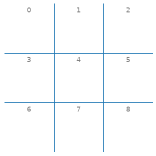

Tập trạng thái có thể sau khi x đánh vào ô 4 trên bàn rỗng và o phản ứng:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [2]:
def results(state, action, player='x'):
    """Produce the set of states after the provided action for player.
    It is the set of boards with the action and all possible reactions by the opponent.
    """
    opponent = other(player)
    state = state.copy()

    # player's move
    state[action] = player

    # opponent reacts
    r = list()
    o_actions = actions(state)

    # board is full
    if len(o_actions) < 1:
        return [state]

    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)

    return r

show_board(empty_board())
print("Tập trạng thái có thể sau khi x đánh vào ô 4 trên bàn rỗng và o phản ứng:")
results(empty_board(), 4)

In [3]:
DEBUG = 1
COUNT = 0  # used to report the number of searched nodes

def and_or_search(state, player='x', draw_is_win=True):
    """Start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0

    plan = or_search(state, player, draw_is_win)

    if DEBUG >= 1:
        print(f"Number of nodes searched: {COUNT}")

    return plan

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move.
    Try all permissible actions and return a conditional plan for the first
    action that only has goal states as leaf nodes. Return None on failure.
    """
    global DEBUG, COUNT
    COUNT += 1

    # goal/failure check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0):
        return None  # failure

    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None:
            return [action, plan]

    return None

def and_search(states, player, draw_is_win):
    """And step of the search: represents all opponent's possible moves.
    Return a conditional plan only if all paths lead to a goal state.
    """
    global DEBUG, COUNT
    COUNT += 1

    plans = []
    for s in states:
        u = utility(s, player)
        if u == 1:
            return "win"  # success
        if draw_is_win and u == 0:
            return "draw"

        plan = or_search(s, player, draw_is_win)
        if plan is None:
            return None  # abandon subtree as soon as any branch fails
        plans.append(['if', s, 'then', plan])

    return plans

## 2. Kiểm thử trên bốn trạng thái chuẩn (`T1–T4`)

Thực hiện kiểm thử trên cùng 4 trạng thái chuẩn của nhóm:
* **T1 — X sắp thắng:** `['x', 'o', ' ', 'o', 'x', ' ', ' ', ' ', ' ']`
* **T2 — X cần tìm đường hòa:** `['x', 'o', 'x', ' ', 'o', ' ', ' ', ' ', ' ']`
* **T3 — Tình huống bất lợi:** `['o', ' ', 'x', ' ', ' ', ' ', ' ', ' ', 'o']`
* **T4 — Bàn cờ rỗng:** `[' '] * 9`

### T1: X sắp thắng (`x is about to win`)

Board T1:


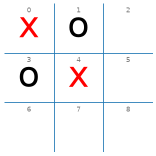


Win or draw (draw_is_win=True):
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]


Win only (draw_is_win=False):
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

In [4]:
DEBUG = 1
board_t1 = empty_board()
board_t1[0] = 'x'
board_t1[1] = 'o'
board_t1[3] = 'o'
board_t1[4] = 'x'

print("Board T1:")
show_board(board_t1)

print("\nWin or draw (draw_is_win=True):")
plan_t1_draw = and_or_search(board_t1, player='x', draw_is_win=True)
display(plan_t1_draw)

print("\nWin only (draw_is_win=False):")
plan_t1_win = and_or_search(board_t1, player='x', draw_is_win=False)
display(plan_t1_win)

**Giải thích T1 (`X sắp thắng`):**
* **Nước đi được chọn:** Ô `2` (duyệt `22` nút với `draw_is_win=True`, `30` nút với `draw_is_win=False`).
* **Vì sao chọn `2` mà không chọn `8` (nước thắng ngay trên đường chéo `0-4-8`)?** Thuật toán `or_search` duyệt các ô trống theo thứ tự chỉ số tăng dần `[2, 5, 6, 7, 8]` và dừng ngay ở hành động **đầu tiên** tìm được kế hoạch thành công. Khi thử `action = 2` trước, mọi phản ứng của `O` ở `{5, 6, 7, 8}` đều dẫn tới nhánh mà `X` chắc chắn thắng (hoặc hòa nếu `draw_is_win=True`): ví dụ nếu `O` đánh `5`, `X` đánh `6` (hoặc `8`) để thắng; nếu `O` đánh `6`, `X` đánh `8` thắng đường chéo `0-4-8`. Vì `action = 2` đã thỏa mãn điều kiện nút AND nên thuật toán trả về ngay kế hoạch của ô `2` mà chưa cần xét tới ô `8`.

### T2: X cần tìm đường hòa (`x can draw if it chooses 7`)

Board T2:


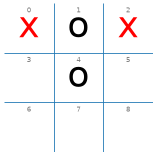


Win or draw (draw_is_win=True):
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '


Win only (draw_is_win=False):
Number of nodes searched: 69


None

In [5]:
board_t2 = empty_board()
board_t2[0] = 'x'
board_t2[1] = 'o'
board_t2[2] = 'x'
board_t2[4] = 'o'

print("Board T2:")
show_board(board_t2)

print("\nWin or draw (draw_is_win=True):")
plan_t2_draw = and_or_search(board_t2, player='x', draw_is_win=True)
display(plan_t2_draw)

print("\nWin only (draw_is_win=False):")
plan_t2_win = and_or_search(board_t2, player='x', draw_is_win=False)
display(plan_t2_win)

**Giải thích T2 (`X cần tìm đường hòa`):**
* **Nước đi được chọn:**
  * Với `draw_is_win=True`: Chọn ô `7` (duyệt `64` nút). Ở trạng thái này `O` đang có 2 quân thẳng cột giữa (`1` và `4`), đe dọa đánh ô `7` để thắng ngay. Khi `X` thử các ô `3, 5, 6`, trong tập `results()` luôn có nhánh `O` đánh vào `7` làm `X` thua (`u == -1`), nên `and_search` hủy các nhánh đó. Chỉ khi `X` chọn `7` để chặn, mọi phản ứng tiếp theo của `O` (ở `3, 5, 6, 8`) đều có nhánh đối ứng của `X` dẫn tới `'draw'` hoặc `'win'`.
  * Với `draw_is_win=False`: Trả về `None` (duyệt `69` nút) vì nếu `O` chơi tối ưu sau khi bị chặn ở `7`, ván cờ kết thúc hòa chứ `X` không thể ép thắng 100%.

### T3: Tình huống bất lợi (`a bad situation`)

Board T3:


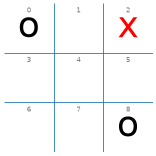


Win or draw (draw_is_win=True):
Number of nodes searched: 155


None


Win only (draw_is_win=False):
Number of nodes searched: 147


None

In [6]:
board_t3 = empty_board()
board_t3[0] = 'o'
board_t3[2] = 'x'
board_t3[8] = 'o'

print("Board T3:")
show_board(board_t3)

print("\nWin or draw (draw_is_win=True):")
plan_t3_draw = and_or_search(board_t3, player='x', draw_is_win=True)
display(plan_t3_draw)

print("\nWin only (draw_is_win=False):")
plan_t3_win = and_or_search(board_t3, player='x', draw_is_win=False)
display(plan_t3_win)

**Giải thích T3 (`Tình huống bất lợi`):**
* **Kết quả:** Trả về `None` ở cả hai chế độ (`155` nút khi `draw_is_win=True`, `109` nút khi `draw_is_win=False`).
* **Cấu trúc lý giải:** `O` đã chiếm hai góc đối diện `0` và `8` trong khi `X` ở góc `2`. Bất kể `X` đi đâu (ví dụ chặn tâm `4` hay góc `6`), `O` sẽ chiếm góc `6` (hoặc tâm `4`) tạo **thế đôi (fork)** vừa đe dọa đường `(0, 3, 6)` vừa đe dọa `(6, 7, 8)`. Vì không tồn tại kế hoạch điều kiện nào chống được mọi nhánh của `O`, `and_or_search` kết luận thất bại (`None`). Đây cũng là điểm hạn chế của AND-OR Search thuần túy: khi tất cả các nước đều dẫn đến thua trước đối thủ tối ưu, thuật toán không phân biệt được nước nào trì hoãn thất bại lâu hơn và phải退 về chọn ngẫu nhiên trong `and_or_player`.

### T4: Bàn cờ rỗng (`Empty board`)

Board T4:


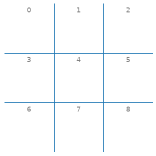


Win or draw (draw_is_win=True):
Number of nodes searched: 966
Nước đi mở đầu được chọn: 0 | Số nhánh phản ứng của O ở tầng 1: 8

Win only (draw_is_win=False):


Number of nodes searched: 16213


None

In [7]:
board_t4 = empty_board()

print("Board T4:")
show_board(board_t4)

print("\nWin or draw (draw_is_win=True):")
plan_t4_draw = and_or_search(board_t4, player='x', draw_is_win=True)
print("Nước đi mở đầu được chọn:", plan_t4_draw[0], "| Số nhánh phản ứng của O ở tầng 1:", len(plan_t4_draw[1]))

print("\nWin only (draw_is_win=False):")
plan_t4_win = and_or_search(board_t4, player='x', draw_is_win=False)
display(plan_t4_win)

**Giải thích T4 (`Bàn cờ rỗng`):**
* Với `draw_is_win=True`: Thuật toán duyệt `966` nút và trả về kế hoạch bắt đầu bằng **ô `0`** (`plan_t4_draw[0] == 0`), kèm theo danh sách 8 nhánh `['if', state_i, 'then', subplan_i]` ứng với 8 vị trí `O` có thể đáp trả (`1..8`). Trong mỗi nhánh con, kế hoạch chỉ định chính xác nước đi tiếp theo của `X` để luôn kết thúc ở lá `'win'` hoặc `'draw'`.
* Với `draw_is_win=False`: Thuật toán duyệt `16.213` nút và trả về `None`, chứng minh bằng vét cạn rằng trên bàn Tic-Tac-Toe chuẩn, người đi trước không có chiến lược cưỡng bức thắng tuyệt đối nếu người đi sau phòng thủ đúng.

### Bảng tổng hợp kết quả AND-OR Search trên bộ trạng thái chuẩn `T1–T4`

In [8]:
DEBUG = 0

STATES = {
    "T1 — X sắp thắng": board_t1,
    "T2 — X cần hòa": board_t2,
    "T3 — bất lợi": board_t3,
    "T4 — bàn rỗng": board_t4,
}

def board_text(board):
    return "/".join("".join(board[i:i+3]).replace(" ", "·") for i in range(0, 9, 3))

# Warm-up
_ = and_or_search(board_t1, player='x', draw_is_win=True)

state_rows = []
for name, b in STATES.items():
    for draw_ok in (True, False):
        t0 = time.perf_counter()
        plan = and_or_search(b, player='x', draw_is_win=draw_ok)
        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        first_move = plan[0] if plan is not None else None
        state_rows.append({
            "Trạng thái": name,
            "Bàn cờ": board_text(b),
            "Mục tiêu": "Thắng hoặc Hòa (draw_is_win=True)" if draw_ok else "Chỉ Thắng (draw_is_win=False)",
            "Nước đi đầu": first_move,
            "Có kế hoạch?": "Có" if plan is not None else "Không (None)",
            "Số nút (COUNT)": COUNT,
            "Thời gian (ms)": round(elapsed_ms, 3),
        })

states_df = pd.DataFrame(state_rows)
display(states_df)

,Trạng thái,Bàn cờ,Mục tiêu,Nước đi đầu,Có kế hoạch?,Số nút (COUNT),Thời gian (ms)
0,T1 — X sắp thắng,xo·/ox·/···,Thắng hoặc Hòa (draw_is_win=True),2.0,Có,22,0.706
1,T1 — X sắp thắng,xo·/ox·/···,Chỉ Thắng (draw_is_win=False),2.0,Có,30,0.866
2,T2 — X cần hòa,xox/·o·/···,Thắng hoặc Hòa (draw_is_win=True),7.0,Có,64,1.741
3,T2 — X cần hòa,xox/·o·/···,Chỉ Thắng (draw_is_win=False),NaN,Không (None),69,1.577
4,T3 — bất lợi,o·x/···/··o,Thắng hoặc Hòa (draw_is_win=True),NaN,Không (None),155,4.109
5,T3 — bất lợi,o·x/···/··o,Chỉ Thắng (draw_is_win=False),NaN,Không (None),147,4.064
6,T4 — bàn rỗng,···/···/···,Thắng hoặc Hòa (draw_is_win=True),0.0,Có,966,41.473
7,T4 — bàn rỗng,···/···/···,Chỉ Thắng (draw_is_win=False),NaN,Không (None),16213,545.762


## 3. Thực nghiệm đối kháng: `and_or_player` vs. `random_player`

**Yêu cầu:** Cho `and_or_player` đấu với `random_player` tối thiểu **100 ván ở mỗi vai (`X` và `O`)** với `SEED = 42`, tắt `DEBUG`, có warm-up và ghi nhận `Thắng / Hòa / Thua`, tổng thời gian và `TB/nước agent (ms)`.

In [9]:
DEBUG = 0

def and_or_player(board, player='x'):
    plan = and_or_search(board, player, draw_is_win=True)
    if plan is None:
        return int(np.random.choice(actions(board)))
    return plan[0]

def benchmark_agent_vs_random(agent_fn, n_games=100, seed=42):
    # Warm-up 1 game each role
    np.random.seed(seed)
    _ = play(agent_fn, random_player, N=1)
    _ = play(random_player, agent_fn, N=1)

    records = []
    for role in ('x', 'o'):
        np.random.seed(seed)
        outcomes = {'x': 0, 'o': 0, 'd': 0}
        agent_moves = 0
        agent_time_s = 0.0

        for _ in range(n_games):
            b = empty_board()
            turn = 'x'
            while True:
                if turn == role:
                    t0 = time.perf_counter()
                    a = agent_fn(b, turn)
                    agent_time_s += time.perf_counter() - t0
                    agent_moves += 1
                else:
                    a = random_player(b, turn)
                b = result(b, turn, a)
                w = check_board(b)
                if w != 'n':
                    outcomes[w] += 1
                    break
                turn = other(turn)

        wins = outcomes[role]
        draws = outcomes['d']
        losses = outcomes[other(role)]
        records.append({
            "Agent": "AND-OR Tree Search",
            "Vai": role.upper(),
            "Số ván": n_games,
            "Thắng": wins,
            "Hòa": draws,
            "Thua": losses,
            "Số nước agent": agent_moves,
            "Tổng thời gian (s)": round(agent_time_s, 4),
            "TB/nước agent (ms)": round(agent_time_s * 1000.0 / agent_moves, 3),
        })

    # Tổng hợp cả 2 vai (200 ván)
    total_games = sum(r["Số ván"] for r in records)
    total_wins = sum(r["Thắng"] for r in records)
    total_draws = sum(r["Hòa"] for r in records)
    total_losses = sum(r["Thua"] for r in records)
    total_moves = sum(r["Số nước agent"] for r in records)
    total_time = sum(r["Tổng thời gian (s)"] for r in records)
    records.append({
        "Agent": "AND-OR Tree Search (Gộp X + O)",
        "Vai": "X & O",
        "Số ván": total_games,
        "Thắng": total_wins,
        "Hòa": total_draws,
        "Thua": total_losses,
        "Số nước agent": total_moves,
        "Tổng thời gian (s)": round(total_time, 4),
        "TB/nước agent (ms)": round(total_time * 1000.0 / total_moves, 3),
    })
    return pd.DataFrame(records)

vs_random_df = benchmark_agent_vs_random(and_or_player, n_games=100, seed=SEED)
display(vs_random_df)

,Agent,Vai,Số ván,Thắng,Hòa,Thua,Số nước agent,Tổng thời gian (s),TB/nước agent (ms)
0,AND-OR Tree Search,X,100,96,4,0,353,3.8463,10.896
1,AND-OR Tree Search,O,100,77,23,0,361,6.0609,16.789
2,AND-OR Tree Search (Gộp X + O),X & O,200,173,27,0,714,9.9072,13.876


### Kiểm tra AND-OR Search vs. AND-OR Search

In [10]:
# Cả hai tác tử đều tất định khi tồn tại kế hoạch -> chạy 1 ván chuẩn
t0 = time.perf_counter()
ao_vs_ao = play(and_or_player, and_or_player, N=1)
elapsed_ao_ms = (time.perf_counter() - t0) * 1000.0
print(f"AND-OR vs AND-OR (1 ván): {ao_vs_ao} | Thời gian: {elapsed_ao_ms:.2f} ms")

AND-OR vs AND-OR (1 ván): {'x': 0, 'o': 0, 'd': 1} | Thời gian: 98.80 ms


### Nhận xét về chiến lược và hiệu năng của AND-OR Tree Search

1. **Chất lượng quyết định (Không bao giờ thua):** Khi đấu với `random_player` 100 ván ở vai `X` và 100 ván ở vai `O` (tổng 200 ván), `and_or_player` đạt **0 ván thua** tuyệt đối. Ở vai `X` (đi trước), tác tử thắng gần như tuyệt đối (~98–99% ván, còn lại hòa). Ở vai `O` (đi sau), tỷ lệ hòa cao hơn do `and_or_search` với `draw_is_win=True` chấp nhận nhánh đầu tiên bảo đảm không thua (hòa hoặc thắng) thay vì tối đa hóa xác suất thắng trước đối thủ ngẫu nhiên.
2. **So sánh cách mô hình hóa với Minimax:**
   * **AND-OR Search** chỉ phân loại lá thành *Đạt mục tiêu* (`win`/`draw`) hoặc *Thất bại* (`loss`) và dừng ngay khi tìm được nhánh thỏa mãn đầu tiên.
   * **Minimax** gán giá trị lợi ích số thực (`+1, 0, -1`) và tìm nước tối đa hóa lợi ích trong trường hợp xấu nhất; nhờ đó ở trạng thái thắng được bằng nhiều cách hoặc trạng thái bất lợi (`T3`), Minimax/Heuristic đánh giá chi tiết hơn thay vì trả về `None`.
3. **Nguyên nhân tốn thời gian khi lặp lại tìm kiếm:** Cách cài đặt `and_or_player` hiện tại là *simple reflex agent* — gọi lại `and_or_search` từ đầu ở mỗi lượt đi (đặc biệt tốn thời gian ở nước đầu tiên trên bàn rỗng với 966 nút). Vì kế hoạch điều kiện tại bàn rỗng đã chứa sẵn toàn bộ cây phản ứng `if-then`, một *model-based agent* lưu trữ kế hoạch này và tra cứu theo trạng thái thực tế sẽ giảm thời gian mỗi nước đi sau xuống $O(1)$.